In [ ]:
# MACHINE LEARNING — LAB 6
# Logistic Regression & KNN Classification

## Student Information

**Name:** Abdul Hussain
**Student ID:** 023-24-0286 
**Section:** H 
**GitHub Profile:** https://github.com/AbdulHussainLehri 
**Kaggle Profile:** https://www.kaggle.com/abdulhussainbrohi

**Dataset:** Telco Customer Churn  
**Target Variable:** Churn  

The objective of this lab is to predict whether a customer will churn or not.
Two new classification algorithms, Logistic Regression and K-Nearest Neighbors (KNN),
will be implemented and compared with Decision Tree and Random Forest.

In [2]:
# ============================================
# IMPORT LIBRARIES
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")


df = pd.read_csv("clean_churn.csv")

print("Dataset loaded successfully!")

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()


print("Missing Values:")
print(df.isnull().sum())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nChurn Values:")
print(df["Churn"].value_counts())

Libraries imported successfully!
Dataset loaded successfully!

First 5 rows:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset Shape:
(7043, 20)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  Paym

## Interpretation

The cleaned Telco Customer Churn dataset was loaded successfully.
The dataset shape, column names, data types, missing values, and 
target variable distribution were checked before preparing the data for machine learning.

In [3]:
#part-2
data = df.copy()

data["Churn"] = data["Churn"].astype(str).str.strip()


data["Churn"] = data["Churn"].replace({
    "No": 0,
    "Yes": 1
})

data["Churn"] = pd.to_numeric(data["Churn"], errors="coerce")

print("Churn values after conversion:")
print(data["Churn"].value_counts())

if "customerID" in data.columns:
    data = data.drop("customerID", axis=1)

X = data.drop("Churn", axis=1)
y = data["Churn"]

X = pd.get_dummies(X, drop_first=True)

X = X.apply(pd.to_numeric, errors="coerce")

valid_rows = X.notna().all(axis=1) & y.notna()

X = X.loc[valid_rows]
y = y.loc[valid_rows]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


print("\n============================================")
print("DATA PREPARATION COMPLETE")
print("============================================")

print("\nTraining data shape:", X_train.shape)
print("Testing data shape :", X_test.shape)

print("\nTraining target values:")
print(y_train.value_counts())

print("\nTesting target values:")
print(y_test.value_counts())

print("\nUnique y_train values:", sorted(y_train.unique()))
print("Unique y_test values :", sorted(y_test.unique()))

print("\nNumber of features:", X_train.shape[1])

print("\nFeature scaling completed successfully!")

Churn values after conversion:
Churn
0    5174
1    1869
Name: count, dtype: int64

DATA PREPARATION COMPLETE

Training data shape: (5634, 30)
Testing data shape : (1409, 30)

Training target values:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing target values:
Churn
0    1035
1     374
Name: count, dtype: int64

Unique y_train values: [np.int64(0), np.int64(1)]
Unique y_test values : [np.int64(0), np.int64(1)]

Number of features: 30

Feature scaling completed successfully!


### Why is the scaler fitted only on training data?

The scaler is fitted only on the training data to prevent data leakage.
Information from the test set should not be used during the training or preprocessing process.
The same fitted scaler is then applied to the test data.

LOGISTIC REGRESSION RESULTS
Accuracy : 0.8070
Precision: 0.6584
Recall   : 0.5668
F1 Score : 0.6092

Confusion Matrix:
[[925 110]
 [162 212]]


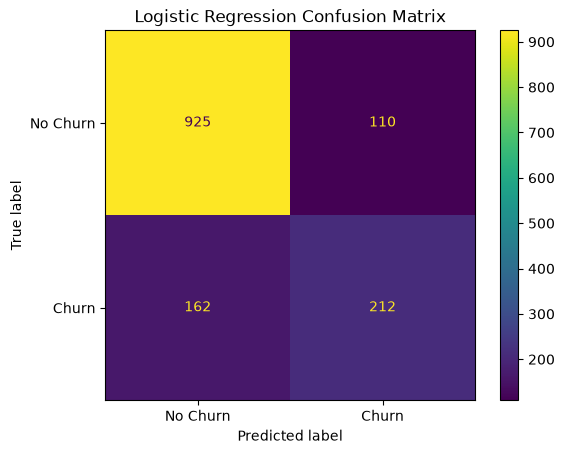


Predicted probabilities for first 10 customers:


,Probability_No_Churn,Probability_Churn
0,0.955018,0.044982
1,0.316766,0.683234
2,0.943458,0.056542
3,0.592194,0.407806
4,0.978334,0.021666
5,0.396462,0.603538
6,0.548127,0.451873
7,0.869075,0.130925
8,0.997148,0.002852
9,0.605855,0.394145


In [4]:
# PART 3 
log_reg = LogisticRegression(max_iter=1000)

log_reg.fit(X_train_scaled, y_train)

y_pred_lr = log_reg.predict(X_test_scaled)

lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, zero_division=0)

print("============================================")
print("LOGISTIC REGRESSION RESULTS")
print("============================================")

print(f"Accuracy : {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall   : {lr_recall:.4f}")
print(f"F1 Score : {lr_f1:.4f}")


cm_lr = confusion_matrix(y_test, y_pred_lr)

print("\nConfusion Matrix:")
print(cm_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title("Logistic Regression Confusion Matrix")
plt.show()


probabilities = log_reg.predict_proba(X_test_scaled)

probability_df = pd.DataFrame(
    probabilities,
    columns=["Probability_No_Churn", "Probability_Churn"]
)

print("\nPredicted probabilities for first 10 customers:")

display(probability_df.head(10))

### Interpretation

The Logistic Regression model was trained on scaled features and evaluated using accuracy, precision, recall, and F1-score.
The confusion matrix shows correct and incorrect predictions for both churn classes.

The `predict_proba()` function provides the estimated probability of each class.
The `predict()` function converts these probabilities into the final class prediction.

KNN RESULTS FOR DIFFERENT K VALUES


,K,Accuracy,Precision,Recall,F1 Score
0,1,0.7161,0.4667,0.4866,0.4764
1,3,0.7438,0.5177,0.5080,0.5128
2,5,0.7473,0.5253,0.5000,0.5123
3,7,0.7594,0.5499,0.5160,0.5324
4,9,0.7693,0.5679,0.5481,0.5578
5,11,0.7729,0.5758,0.5481,0.5616
6,15,0.7700,0.5710,0.5374,0.5537
7,21,0.7708,0.5702,0.5535,0.5617



Selected K based on highest F1 Score: 21


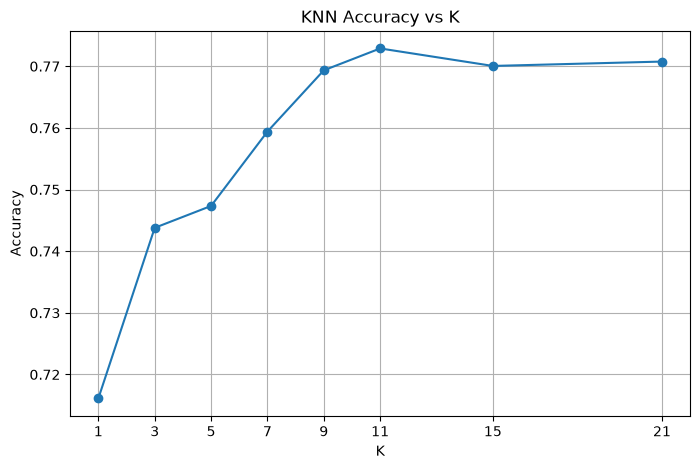

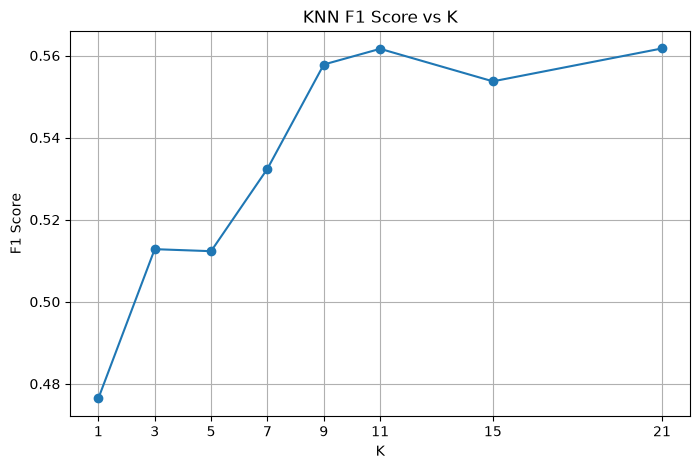


FINAL KNN RESULTS
Selected K: 21
Accuracy  : 0.7708
Precision : 0.5702
Recall    : 0.5535
F1 Score  : 0.5617

KNN Confusion Matrix:
[[879 156]
 [167 207]]


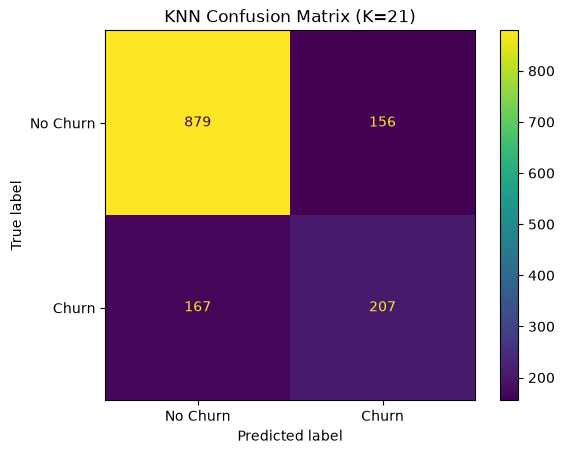

In [12]:
# PART 4 
k_values = [1, 3, 5, 7, 9, 11, 15, 21]

knn_results = []

for k in k_values:
    
    knn_model = KNeighborsClassifier(n_neighbors=k)
    
    knn_model.fit(X_train_scaled, y_train)
    
    y_pred = knn_model.predict(X_test_scaled)
    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    
    knn_results.append({
        "K": k,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

knn_results_df = pd.DataFrame(knn_results)

print("============================================")
print("KNN RESULTS FOR DIFFERENT K VALUES")
print("============================================")

display(knn_results_df.round(4))

best_k = int(
    knn_results_df.loc[
        knn_results_df["F1 Score"].idxmax(),
        "K"
    ]
)

print(f"\nSelected K based on highest F1 Score: {best_k}")

plt.figure(figsize=(8, 5))

plt.plot(
    knn_results_df["K"],
    knn_results_df["Accuracy"],
    marker="o"
)

plt.xlabel("K")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy vs K")
plt.xticks(k_values)
plt.grid(True)

plt.show()

plt.figure(figsize=(8, 5))

plt.plot(
    knn_results_df["K"],
    knn_results_df["F1 Score"],
    marker="o"
)

plt.xlabel("K")
plt.ylabel("F1 Score")
plt.title("KNN F1 Score vs K")
plt.xticks(k_values)
plt.grid(True)

plt.show()

final_knn = KNeighborsClassifier(
    n_neighbors=best_k
)

final_knn.fit(X_train_scaled, y_train)

y_pred_knn = final_knn.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_precision = precision_score(y_test, y_pred_knn, zero_division=0)
knn_recall = recall_score(y_test, y_pred_knn, zero_division=0)
knn_f1 = f1_score(y_test, y_pred_knn, zero_division=0)

print("\n============================================")
print("FINAL KNN RESULTS")
print("============================================")

print(f"Selected K: {best_k}")
print(f"Accuracy  : {knn_accuracy:.4f}")
print(f"Precision : {knn_precision:.4f}")
print(f"Recall    : {knn_recall:.4f}")
print(f"F1 Score  : {knn_f1:.4f}")

cm_knn = confusion_matrix(y_test, y_pred_knn)

print("\nKNN Confusion Matrix:")
print(cm_knn)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title(f"KNN Confusion Matrix (K={best_k})")
plt.show()

### Interpretation

Several K values were tested rather than selecting only one value.
The selected K is based on the highest F1-score obtained in the experiment.

A very small K can be sensitive to individual observations and noise, while a very large K can make the model underfit by considering too many neighboring observations.

In [8]:
#part-5
decision_tree = DecisionTreeClassifier(
    random_state=42
)

decision_tree.fit(X_train, y_train)

y_pred_dt = decision_tree.predict(X_test)

dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt, zero_division=0)
dt_recall = recall_score(y_test, y_pred_dt, zero_division=0)
dt_f1 = f1_score(y_test, y_pred_dt, zero_division=0)

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, zero_division=0)

comparison = pd.DataFrame({

    "Model": [
        "Decision Tree",
        "Random Forest",
        "Logistic Regression",
        "KNN"
    ],

    "Accuracy": [
        dt_accuracy,
        rf_accuracy,
        lr_accuracy,
        knn_accuracy
    ],

    "Precision": [
        dt_precision,
        rf_precision,
        lr_precision,
        knn_precision
    ],

    "Recall": [
        dt_recall,
        rf_recall,
        lr_recall,
        knn_recall
    ],

    "F1 Score": [
        dt_f1,
        rf_f1,
        lr_f1,
        knn_f1
    ]
})

print("============================================")
print("FOUR MODEL COMPARISON")
print("============================================")

display(
    comparison.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

FOUR MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.7260,0.4838,0.4786,0.4812
1,Random Forest,0.7850,0.6179,0.4973,0.5511
2,Logistic Regression,0.8070,0.6584,0.5668,0.6092
3,KNN,0.7708,0.5702,0.5535,0.5617


### Interpretation

The four models were evaluated using the same test set and the same four evaluation metrics.
Accuracy measures overall correctness, while precision, recall, and F1-score provide additional information about the classification performance.

Because customer churn can involve class imbalance, accuracy should not be considered alone.

In [9]:
# PART 6 

feature_names = X.columns

coefficients = log_reg.coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})


coef_df["Odds Ratio"] = np.exp(coef_df["Coefficient"])


coef_df["Absolute Coefficient"] = abs(
    coef_df["Coefficient"]
)

coef_df = coef_df.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

coef_df = coef_df.drop(
    "Absolute Coefficient",
    axis=1
)


print("============================================")
print("LOGISTIC REGRESSION COEFFICIENTS")
print("============================================")

display(
    coef_df.style.format({
        "Coefficient": "{:.4f}",
        "Odds Ratio": "{:.4f}"
    })
)

LOGISTIC REGRESSION COEFFICIENTS


,Feature,Coefficient,Odds Ratio
1,tenure,-1.2365,0.2904
2,MonthlyCharges,-0.9202,0.3985
10,InternetService_Fiber optic,0.7762,2.1731
25,Contract_Two year,-0.5869,0.5561
3,TotalCharges,0.5143,1.6724
24,Contract_One year,-0.2855,0.7516
23,StreamingMovies_Yes,0.2572,1.2933
21,StreamingTV_Yes,0.2571,1.2932
9,MultipleLines_Yes,0.2162,1.2413
26,PaperlessBilling_Yes,0.1820,1.1997


In [10]:
top_4_features = coef_df.head(4)

print("Top 4 features by absolute coefficient:")
display(
    top_4_features.style.format({
        "Coefficient": "{:.4f}",
        "Odds Ratio": "{:.4f}"
    })
)

Top 4 features by absolute coefficient:


,Feature,Coefficient,Odds Ratio
1,tenure,-1.2365,0.2904
2,MonthlyCharges,-0.9202,0.3985
10,InternetService_Fiber optic,0.7762,2.1731
25,Contract_Two year,-0.5869,0.5561


### Interpretation

A positive coefficient indicates that an increase in the corresponding feature is associated with higher log-odds of churn, while a negative coefficient indicates lower log-odds of churn, holding other variables constant.

The odds ratio is calculated using `exp(coefficient)`.
An odds ratio greater than 1 indicates increased odds, while an odds ratio below 1 indicates decreased odds.

In [13]:
print("Best Accuracy:")
print(comparison.loc[
    comparison["Accuracy"].idxmax()
])

print("\nBest Precision:")
print(comparison.loc[
    comparison["Precision"].idxmax()
])

print("\nBest Recall:")
print(comparison.loc[
    comparison["Recall"].idxmax()
])

print("\nBest F1 Score:")
print(comparison.loc[
    comparison["F1 Score"].idxmax()
])

Best Accuracy:
Model        Logistic Regression
Accuracy                0.806955
Precision               0.658385
Recall                  0.566845
F1 Score                0.609195
Name: 2, dtype: object

Best Precision:
Model        Logistic Regression
Accuracy                0.806955
Precision               0.658385
Recall                  0.566845
F1 Score                0.609195
Name: 2, dtype: object

Best Recall:
Model        Logistic Regression
Accuracy                0.806955
Precision               0.658385
Recall                  0.566845
F1 Score                0.609195
Name: 2, dtype: object

Best F1 Score:
Model        Logistic Regression
Accuracy                0.806955
Precision               0.658385
Recall                  0.566845
F1 Score                0.609195
Name: 2, dtype: object


## Conclusion
In this lab, Logistic Regression and KNN were implemented for the Telco Customer Churn classification problem.
Feature scaling was applied because KNN relies on distance calculations and Logistic Regression benefits from features being on comparable scales.
Several K values were tested for KNN, and the selected value was based on the F1-score results.
The four models were compared using accuracy, precision, recall, and F1-score.
The comparison showed that model performance can vary depending on the evaluation metric being considered.
The main limitation of the current evaluation is that it uses a single train-test split, so additional cross-validation could provide a more reliable estimate of generalization performance.
Future work could include further hyperparameter tuning and additional validation experiments.